## Pratica dos conteúdos aprendidos no CARD 5

Usei todos os conteudos aprendidos na seção do curso aqui, segui a mesma ordem do curso.

### Setup

In [1]:
# Peguei esse dataframe pra treinar, citação: Fanaee-T, H. (2013). Bike Sharing [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5W894. Link para o dataset: https://archive.ics.uci.edu/ml/datasets/bike+sharing+dataset
import numpy as np, pandas as pd, seaborn as sns, matplotlib.pyplot as plt
import scipy
from scipy.stats import norm, binom, poisson, expon
df = pd.read_csv('hour.csv')

In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB


In [3]:
df.head(30)

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0000,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0000,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0000,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0000,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0000,0,1,1
5,6,2011-01-01,1,0,1,5,0,6,0,2,0.24,0.2576,0.75,0.0896,0,1,1
6,7,2011-01-01,1,0,1,6,0,6,0,1,0.22,0.2727,0.80,0.0000,2,0,2
7,8,2011-01-01,1,0,1,7,0,6,0,1,0.20,0.2576,0.86,0.0000,1,2,3
8,9,2011-01-01,1,0,1,8,0,6,0,1,0.24,0.2879,0.75,0.0000,1,7,8
9,10,2011-01-01,1,0,1,9,0,6,0,1,0.32,0.3485,0.76,0.0000,8,6,14


### Mean, Median and Mode

In [4]:
np.mean(df['cnt'])# Aparentemente tem bastante outliers

np.float64(189.46308763450142)

In [5]:
np.median(df['cnt']) #mais de 40 de diff

np.float64(142.0)

In [6]:
scipy.stats.mode(df['cnt']) # 5

ModeResult(mode=np.int64(5), count=np.int64(260))

### Std and Variance

In [7]:
np.var(df['cnt'])

np.float64(32899.567930877354)

In [8]:
np.var(df['weathersit'])

np.float64(0.40875369580034027)

In [9]:
np.std(df['cnt'])

np.float64(181.3823804311691)

In [10]:
np.std(df['weathersit'])

np.float64(0.6393384829652758)

## PMF and PDF

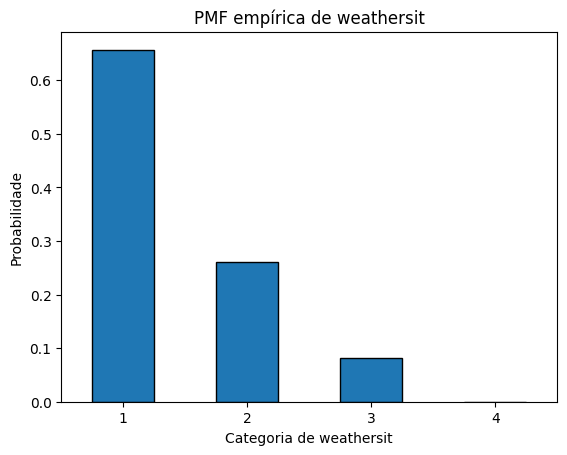

In [11]:
PMF = df["weathersit"].value_counts(normalize=True).sort_index()

PMF.plot.bar(edgecolor="black")
plt.xlabel("Categoria de weathersit")
plt.ylabel("Probabilidade")
plt.title("PMF empírica de weathersit")
plt.xticks(rotation=0)
plt.show()

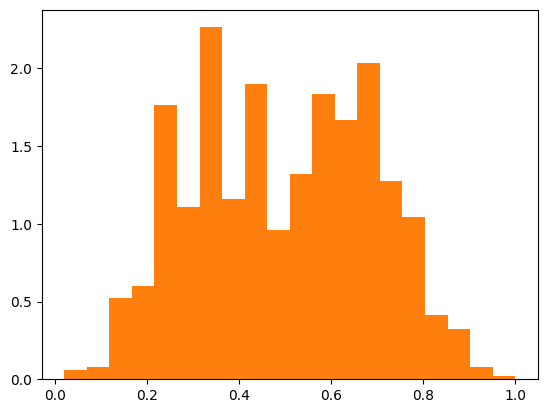

In [12]:
densidades, limites, _ = plt.hist(df["temp"].dropna(), bins=20, density=True)
plt.hist(df["temp"].dropna(), bins=20, density=True)
plt.show()

### Distributions 

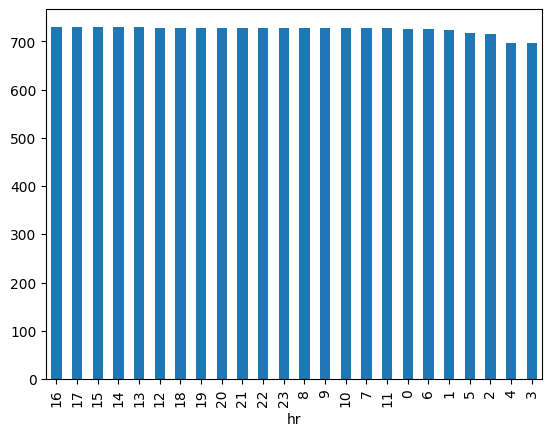

In [13]:
# Uniforme
un = df["hr"].value_counts()
un.plot.bar()
plt.show() # a hr é prticamente uniforme 

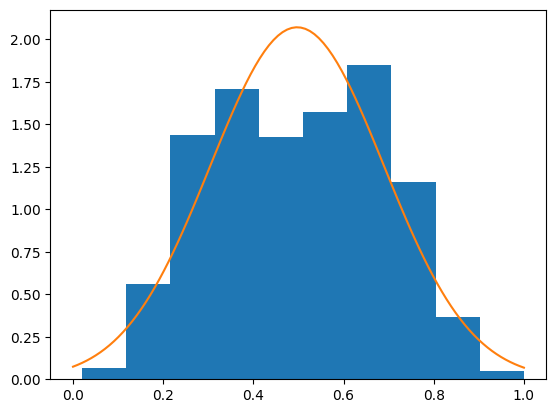

In [14]:
# Normal
x = np.linspace(0, 1, 100) # pra usar pra comparar só
media = np.mean(df["temp"])
desvio = np.std(df["temp"])
plt.hist(df["temp"], density=True)
plt.plot(x, norm.pdf(x, media, desvio))
plt.show()

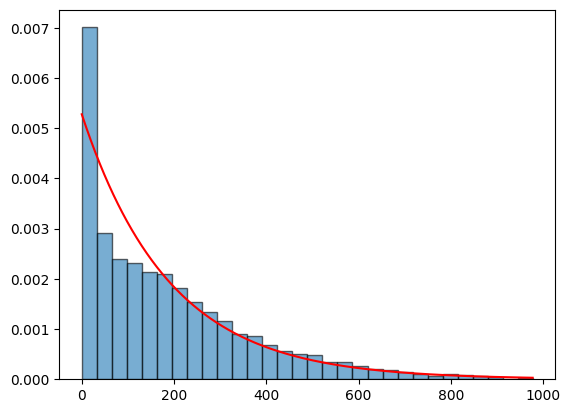

In [15]:
# exp
cnt = df["cnt"].dropna()
media = cnt.mean()
x = np.linspace(0, cnt.max(), 1000)
plt.hist(cnt, bins=30, density=True, edgecolor="black", alpha=0.6)
plt.plot(x, expon.pdf(x, scale=media), color="red")
plt.show() # coincidiram bem

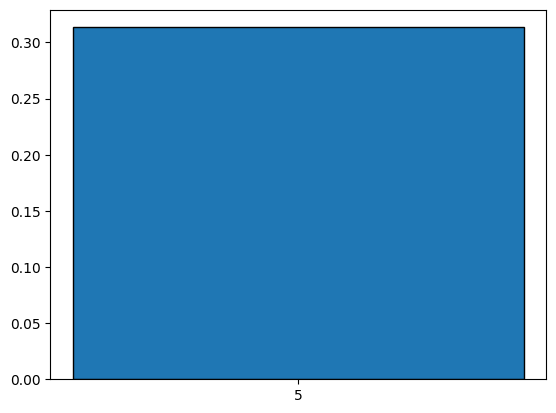

In [16]:
# binomial da da chance de estar entre 5 e 7 
p = df["workingday"].mean()
bn = binom.pmf(5, 7, p)

plt.bar([5], [bn], edgecolor="black")
plt.xticks([5])
plt.show()

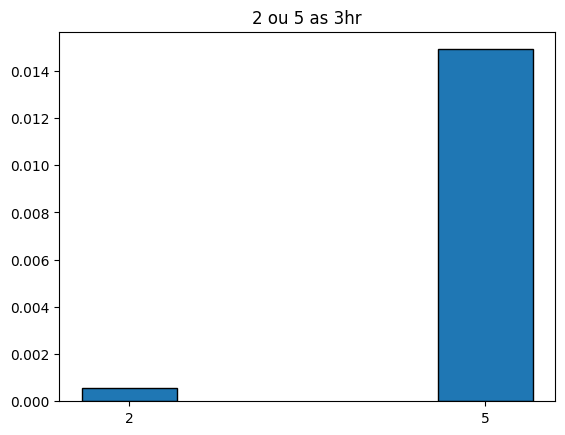

In [17]:
#poisson
mu = df[df["hr"] == 3]["cnt"].mean()
p2 = poisson.pmf(2, mu)
p5 = poisson.pmf(5, mu)

plt.bar([2, 5], [p2, p5], edgecolor="black")
plt.xticks([2, 5])
plt.title("2 ou 5 as 3hr")
plt.show()

### Percentiles

In [18]:
np.percentile(df["cnt"], [25, 50, 75]) # 25 por cento dos valores é menor que 40 a mediana ér 142 e 57% dos é menor 281

array([ 40., 142., 281.])

### Moments

In [19]:
#1
m = np.mean(df['cnt'])
#2
v = np.var(df['cnt'])
#3
s = scipy.stats.skew(df['cnt'])
#4
k = scipy.stats.kurtosis(df['cnt'])

print(f"Media: {m} var: {v} skew: {s} kurtosis: {k}")

Media: 189.46308763450142 var: 32899.567930877354 skew: 1.277301346349497 kurtosis: 1.416450354688739


### MatPlotLib

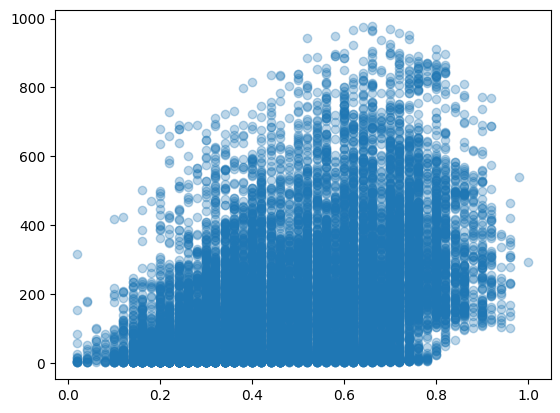

In [20]:
plt.scatter(df["temp"], df["cnt"], alpha=0.3) # dispersão vertical inclinada pra direita

{'whiskers': [<matplotlib.lines.Line2D at 0x2789297e710>,
 'caps': [<matplotlib.lines.Line2D at 0x2789297e990>,
 'boxes': [<matplotlib.lines.Line2D at 0x27892b2e210>],
 'medians': [<matplotlib.lines.Line2D at 0x2789297ec10>],
 'fliers': [<matplotlib.lines.Line2D at 0x2789297ed50>],
 'means': []}

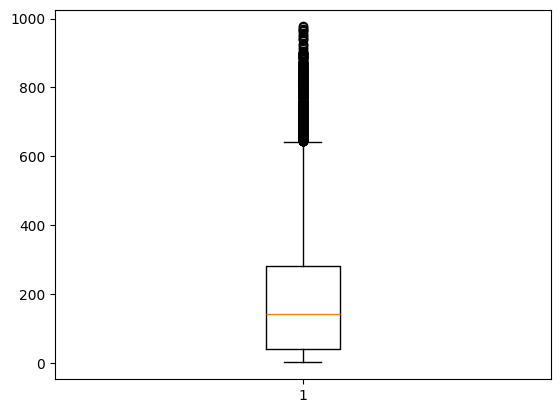

In [21]:
plt.boxplot(df["cnt"]) # maior parte dos numeros dentro de 40 - 281 mas os dados vão até 600~ e tem bastante outliers

### Seaborn

<Axes: >

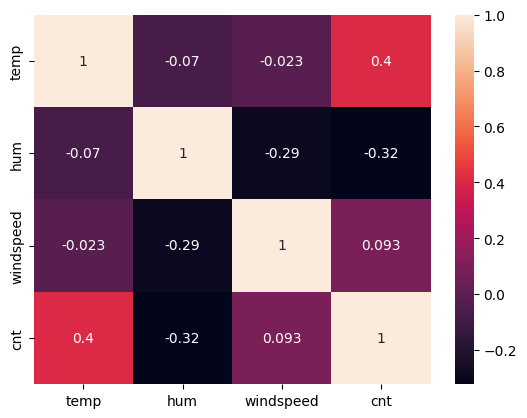

In [22]:
sns.heatmap(df[["temp", "hum", "windspeed", "cnt"]].corr(), annot=True) # temp praticamete linear 

<Axes: xlabel='weathersit', ylabel='cnt'>

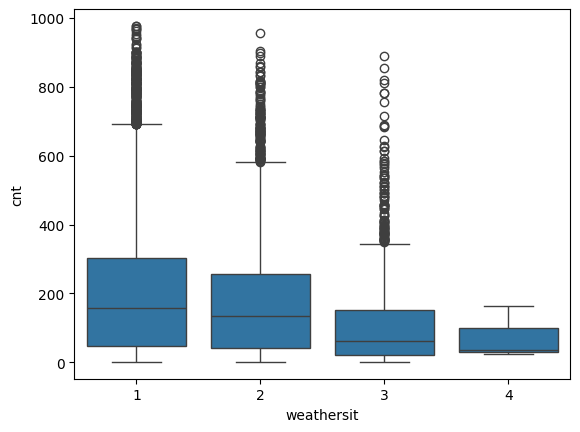

In [23]:
sns.boxplot(x="weathersit", y="cnt", data=df) # no 1,2,3 os dados tem bastante outliers e no 4 nem tem mas o dominio dele também é bem menor

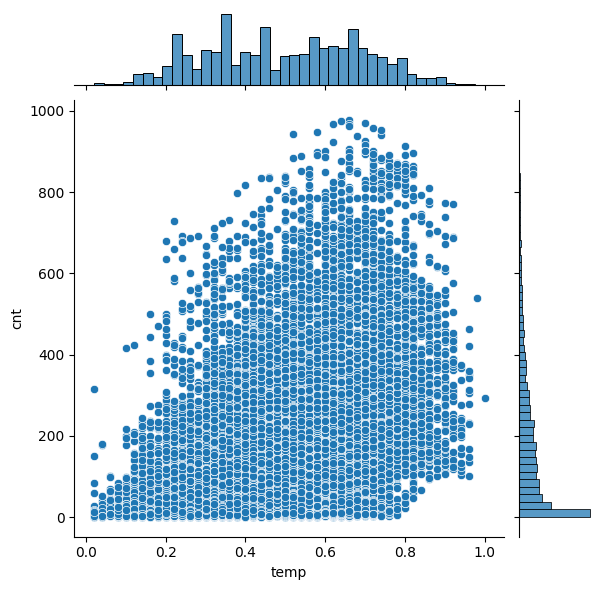

In [24]:
sns.jointplot(x="temp", y="cnt", data=df) # os dados estão bem dispersos tmp mais centrado na média e cnt mais forte no 4 quartil deixando o grafigo mais vertical

### Covariance and Correlation

In [25]:
np.cov(df["temp"], df["cnt"]) # cov positivo aparentemente tem cov

array([[3.70778598e-02, 1.41375997e+01],
       [1.41375997e+01, 3.29014611e+04]])

In [26]:
np.corrcoef(df["temp"], df["cnt"]) # 40 de covariância no cov normalizado

array([[1.        , 0.40477228],
       [0.40477228, 1.        ]])

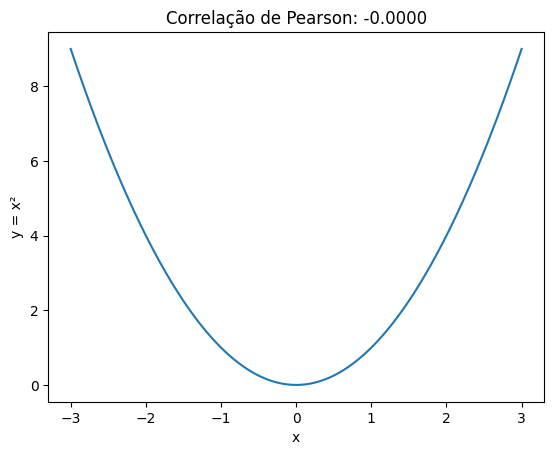

In [27]:
x = np.linspace(-3, 3, 200)
y = x**2
correlacao = np.corrcoef(x, y)[0, 1]

plt.plot(x, y)
plt.xlabel("x")
plt.ylabel("y = x²")
plt.title(f"Correlação de Pearson: {correlacao:.4f}")
plt.show() # deu zero ma spode se que tenha um correlação memso que não linear

### Conditional Probability

In [28]:
alto = df["cnt"] > df["cnt"].mean()
p1 = alto.mean()
p2 = alto[df["workingday"] == 1].mean()
p3 = alto[df["weathersit"] == 3].mean()

p1, p2, p3
# 40 por cento alugueis tao acima da média
# nos dias uteis 41%
# no clima 3 só 20%

(np.float64(0.3990448242131308),
 np.float64(0.41053518752633794),
 np.float64(0.19097956307258632))